In [1]:
import numpy as np;
import pandas as pd;
import matplotlib.pyplot as plt;
import seaborn as sns;
from urllib.parse import urlparse

In [2]:
df = pd.read_csv('./Data/data.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 504983 entries, 0 to 504982
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   url     504983 non-null  str  
 1   Type    504983 non-null  str  
dtypes: str(2)
memory usage: 41.6 MB


In [4]:
df.columns

Index(['url', 'Type'], dtype='str')

In [5]:
df.shape

(504983, 2)

In [6]:
df.isna().sum()

url     0
Type    0
dtype: int64

In [7]:
df.drop_duplicates(inplace=True)
df.shape

(504932, 2)

In [8]:
df.isnull().sum()

url     0
Type    0
dtype: int64

In [9]:
df['Type'].value_counts()

Type
legitimate    345738
Phishing      159194
Name: count, dtype: int64

In [10]:
df['isHTTP'] = df['url'].apply(lambda x: 1 if x.startswith('https') else 0)

In [11]:
df['length'] = df['url'].apply(lambda x: len(x))

In [12]:
df['isSpeacialChar'] = df['url'].apply(lambda x: 1 if not x.isalnum() else 0)

In [13]:
import ipaddress
def extract_tld(url):
    try:
        hostname = urlparse(url).hostname or 'N/A'

        # Ignore IPv4 and IPv6 addresses
        try:
            ipaddress.ip_address(hostname)
            return ''
        except ValueError:
            parts = hostname.split('.')
            if len(parts) > 1:
                return parts[-1]
            else:
                return ''
    except (ValueError, TypeError):
        return ''

df['TLD'] = df['url'].apply(extract_tld)

In [14]:
df

,url,Type,isHTTP,length,isSpeacialChar,TLD
0,https://docs.google.com/presentation/d/e/2PACX...,Phishing,1,178,1,com
1,https://btttelecommunniccatiion.weeblysite.com/,Phishing,1,47,1,com
2,https://kq0hgp.webwave.dev/,Phishing,1,27,1,dev
3,https://brittishtele1bt-69836.getresponsesite....,Phishing,1,50,1,com
4,https://bt-internet-105056.weeblysite.com/,Phishing,1,42,1,com
...,...,...,...,...,...,...
504978,http://ecct-it.com/docmmmnn/aptgd/index.php,Phishing,0,43,1,com
504979,http://faboleena.com/js/infortis/jquery/plugin...,Phishing,0,159,1,com
504980,http://faboleena.com/js/infortis/jquery/plugin...,Phishing,0,147,1,com
504981,http://atualizapj.com/,Phishing,0,22,1,com


In [15]:
df['isDot'] = df['url'].apply(lambda x: sum(1 for c in x if c == '.'))
df['isDash'] = df['url'].apply(lambda x: sum(1 for c in x if c == '-'))
df['isSlash'] = df['url'].apply(lambda x: sum(1 for c in x if c == '/'))
df['isQuestionMark'] = df['url'].apply(lambda x: sum(1 for c in x if c == '?'))
df['isEqual'] = df['url'].apply(lambda x: sum(1 for c in x if c == '='))  
df['isNumber'] = df['url'].apply(lambda x: sum(1 for c in x if c.isdigit()))
df['isChar'] = df['url'].apply(lambda x: sum(1 for c in x if c.isalpha()))

In [16]:
from urllib.parse import urlparse, parse_qsl

def extract_structure_features(url):
    url = str(url).strip()

    try:
        parsed = urlparse(url if "://" in url else f"//{url}")
        path = parsed.path or ""
        query = parsed.query or ""
    except ValueError:
        path = ""
        query = ""

    return pd.Series({
        "path_depth": sum(bool(part) for part in path.split("/")),
        "query_param_count": len(
            parse_qsl(query, keep_blank_values=True)
        ),
    })

new_features = df["url"].apply(extract_structure_features)
df = pd.concat([df, new_features], axis=1)

df[["url", "path_depth", "query_param_count"]].head()

,url,path_depth,query_param_count
0,https://docs.google.com/presentation/d/e/2PACX...,5,4
1,https://btttelecommunniccatiion.weeblysite.com/,0,0
2,https://kq0hgp.webwave.dev/,0,0
3,https://brittishtele1bt-69836.getresponsesite....,0,0
4,https://bt-internet-105056.weeblysite.com/,0,0


In [17]:
df

,url,Type,isHTTP,length,isSpeacialChar,TLD,isDot,isDash,isSlash,isQuestionMark,isEqual,isNumber,isChar,path_depth,query_param_count
0,https://docs.google.com/presentation/d/e/2PACX...,Phishing,1,178,1,com,3,3,7,1,4,20,135,5,4
1,https://btttelecommunniccatiion.weeblysite.com/,Phishing,1,47,1,com,2,0,3,0,0,0,41,0,0
2,https://kq0hgp.webwave.dev/,Phishing,1,27,1,dev,2,0,3,0,0,1,20,0,0
3,https://brittishtele1bt-69836.getresponsesite....,Phishing,1,50,1,com,2,1,3,0,0,6,37,0,0
4,https://bt-internet-105056.weeblysite.com/,Phishing,1,42,1,com,2,2,3,0,0,6,28,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
504978,http://ecct-it.com/docmmmnn/aptgd/index.php,Phishing,0,43,1,com,2,1,5,0,0,0,34,3,0
504979,http://faboleena.com/js/infortis/jquery/plugin...,Phishing,0,159,1,com,2,0,14,0,1,21,118,12,0
504980,http://faboleena.com/js/infortis/jquery/plugin...,Phishing,0,147,1,com,1,0,14,0,1,20,109,11,0
504981,http://atualizapj.com/,Phishing,0,22,1,com,1,0,3,0,0,0,17,0,0


<Axes: xlabel='Type', ylabel='count'>

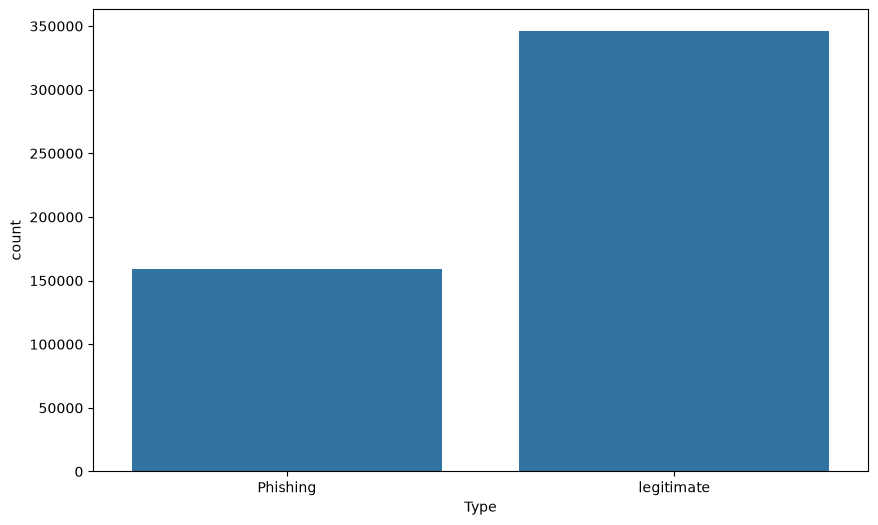

In [18]:
plt.figure(figsize=(10, 6))
sns.countplot(x='Type', data=df)


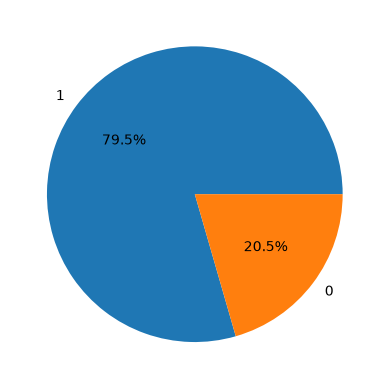

In [19]:
plt.pie(df['isHTTP'].value_counts(), labels=df['isHTTP'].value_counts().index, autopct='%1.1f%%')

In [20]:
from sklearn.preprocessing import OneHotEncoder,TargetEncoder,LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split,StratifiedKFold,GridSearchCV

In [21]:
# Calculate the frequency of each TLD
tld_frequency = df['TLD'].value_counts(normalize=True)

# Encode the TLD column
df['TLD_Frequency'] = df['TLD'].map(tld_frequency)

# Drop the original column if no longer required
df.drop(columns=['TLD'], inplace=True)

In [33]:
std = ['length','isNumber','isChar','isDot','isDash','isSlash','isQuestionMark','isEqual','path_depth','query_param_count']


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

preprocessing = ColumnTransformer([
    ('StandardScaler', StandardScaler(), std)],remainder='passthrough')


In [35]:
preprocessing

,transformers,"[('StandardScaler', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,copy,True
,with_mean,True
,with_std,True


In [36]:
X = df.drop(['url','Type'], axis=1)
y = df['Type']


In [37]:
xTrain, xTest, yTrain, yTest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=df['Type'])

In [38]:
xTrainEncoder = preprocessing.fit_transform(xTrain)
xTestEncoder = preprocessing.transform(xTest)

In [39]:
del LabelEncoder

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

yTrainEncoder = label_encoder.fit_transform(yTrain)
yTestEncoder = label_encoder.transform(yTest)

In [40]:
from sklearn.ensemble import RandomForestClassifier 
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score,f1_score,precision_score,recall_score

model = RandomForestClassifier(n_estimators=100, random_state=42,class_weight='balanced')
model.fit(xTrainEncoder, yTrainEncoder)
yPred = model.predict(xTestEncoder)
model_accuracy = accuracy_score(yTestEncoder, yPred)
model_f1 = f1_score(yTestEncoder, yPred)
model_classification_report = classification_report(yTestEncoder, yPred)
    
print("Accuracy:", model_accuracy)
print("F1 Score:", model_f1)
print("Classification Report:")
print(model_classification_report)


Accuracy: 0.9739075326527177
F1 Score: 0.981079237425053
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.94      0.96     31839
           1       0.97      0.99      0.98     69148

    accuracy                           0.97    100987
   macro avg       0.97      0.97      0.97    100987
weighted avg       0.97      0.97      0.97    100987



In [41]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier

# Define the cross-validation strategy
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Your Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Define evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

# Perform cross-validation
cv_results = cross_validate(
    rf_model,
    xTrainEncoder,
    yTrainEncoder,
    cv=skf,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

# Display results for each fold
for i in range(5):
    print(f"\nFold {i + 1}")
    print(f"Accuracy:  {cv_results['test_accuracy'][i]:.4f}")
    print(f"Precision: {cv_results['test_precision'][i]:.4f}")
    print(f"Recall:    {cv_results['test_recall'][i]:.4f}")
    print(f"F1-score:  {cv_results['test_f1'][i]:.4f}")
    print(f"ROC-AUC:   {cv_results['test_roc_auc'][i]:.4f}")

# Calculate average and standard deviation
print("\n========== Cross-Validation Summary ==========")

for metric in scoring:
    scores = cv_results[f'test_{metric}']

    print(
        f"{metric}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )


Fold 1
Accuracy:  0.9749
Precision: 0.9716
Recall:    0.9924
F1-score:  0.9819
ROC-AUC:   0.9904

Fold 2
Accuracy:  0.9752
Precision: 0.9721
Recall:    0.9922
F1-score:  0.9821
ROC-AUC:   0.9907

Fold 3
Accuracy:  0.9747
Precision: 0.9721
Recall:    0.9915
F1-score:  0.9817
ROC-AUC:   0.9909

Fold 4
Accuracy:  0.9740
Precision: 0.9715
Recall:    0.9912
F1-score:  0.9812
ROC-AUC:   0.9906

Fold 5
Accuracy:  0.9749
Precision: 0.9714
Recall:    0.9925
F1-score:  0.9818
ROC-AUC:   0.9913

========== Cross-Validation Summary ==========
accuracy: 0.9747 +/- 0.0004
precision: 0.9717 +/- 0.0003
recall: 0.9920 +/- 0.0005
f1: 0.9817 +/- 0.0003
roc_auc: 0.9908 +/- 0.0003


In [46]:
import pickle

with open("random_forest_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)

print("Model saved successfully!")

Model saved successfully!


In [47]:
import pickle

with open("random_forest_model.pkl", "rb") as file:
    rf_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!
